# 12 — SOLETE cross-architecture feature comparison

## Purpose

We combine the **completed Ridge, Random Forest, LightGBM, LSTM, GRU, bidirectional LSTM, and TCN development experiments** into a single SOLETE analysis. The archived experiments contain 1,665 candidate–fold evaluations across three forecast horizons, five nested feature families, and three chronological validation folds.

We first report the complete **F0 → F1 → F2 → F3 → F4** progression. Our principal representation comparison is **F3 versus F4** at the same architecture, forecast horizon, and candidate configuration. We separately show the best development-selected candidate within each family and compare the original LightGBM archive with our current Notebook 08 results.

The archived scores are development-validation results in **kW**, not a new test set. Model training and its checkpoints were verified in Notebooks 12 and 13. This notebook reads those verified summaries, performs comparisons, and saves a SOLETE-only synthesis.

## 1. Experimental definitions and archived model populations

F0 uses historical PV power and weather; F1 adds Gregorian variables; F2 adds solar geometry; F3 adds continuous lunar and Sun–Moon geometry; F4 adds 97 Panchang indicators. The forecast horizons are 15, 30, and 60 minutes. The classical and neural archives use the same three chronological development-fold populations, with a 60-minute training-label availability gap.

The classical archive covers Ridge (5 configurations), LightGBM (8), and Random Forest (8). The neural archive covers LSTM, GRU, BiLSTM, and TCN (4 configurations each). Each model–horizon–family–configuration candidate has three fold scores. The archived training records are read without fitting a new model.

In [1]:
from pathlib import Path
from itertools import product
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next((p for p in (Path.cwd().resolve(), Path.cwd().resolve().parent)
                     if (p / 'src' / 'forecasting_protocol.py').is_file()), None)
assert PROJECT_ROOT is not None, 'Run inside the SOLETE repository or its notebooks folder'
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RESULTS = PROJECT_ROOT / 'results' / 'model_architectures'
OUTPUT = PROJECT_ROOT / 'results' / 'solete_architecture_synthesis'
HORIZONS = (15, 30, 60)
FAMILIES = ('F0', 'F1', 'F2', 'F3', 'F4')
MODELS = ('Ridge', 'RandomForest', 'LightGBM', 'LSTM', 'GRU', 'BiLSTM', 'TCN')
CONFIG_COUNTS = {'Ridge':5,'RandomForest':8,'LightGBM':8,
                 'LSTM':4,'GRU':4,'BiLSTM':4,'TCN':4}

required = {
    'classical_fold_scores.csv':945,
    'neural_fold_scores.csv':720,
    'classical_candidate_rankings.csv':315,
    'neural_candidate_rankings.csv':240,
    'classical_family_winners.csv':45,
    'neural_family_winners.csv':60,
}
inputs={}
for filename, expected in required.items():
    path=RESULTS/filename
    if not path.is_file():
        raise FileNotFoundError(f'Run and save Notebooks 12 and 13 first: {path}')
    frame=pd.read_csv(path)
    assert len(frame)==expected, (filename,len(frame),expected)
    inputs[filename]=frame
print('SOLETE classical and neural archive summaries loaded:',sum(required.values()),'table rows')
print('No model fitting or PVOD data access in this notebook')

SOLETE classical and neural archive summaries loaded: 2325 table rows
No model fitting or PVOD data access in this notebook


## 2. Verify cross-architecture sample and score alignment

The previous two notebooks audited the original checksums, source fingerprints, neural input hashes, and checkpoints. Here we independently reconcile the saved fold scores: unique candidate keys, complete configuration grids, shared training/validation row counts, nonnegative MAE/RMSE, and three folds per candidate. These checks ensure the seven-architecture comparison uses the same documented development populations.

In [2]:
COLUMNS = ['model','horizon_minutes','feature_family','config_index','candidate_id',
           'configuration_json','fold','train_rows','validation_rows',
           'validation_mae_kw','validation_rmse_kw']
classical=inputs['classical_fold_scores.csv']
neural=inputs['neural_fold_scores.csv']
assert set(COLUMNS).issubset(classical.columns)
assert set(COLUMNS).issubset(neural.columns)
cv = pd.concat([classical[COLUMNS],neural[COLUMNS]],ignore_index=True)
KEY = ['model','horizon_minutes','feature_family','config_index','fold']
expected_keys=set().union(*(set(product((m,),HORIZONS,FAMILIES,range(c),(1,2,3)))
                            for m,c in CONFIG_COUNTS.items()))
actual_keys=set(cv[KEY].itertuples(index=False,name=None))
assert len(cv)==len(actual_keys)==len(expected_keys)==1665 and actual_keys==expected_keys
assert not cv.duplicated(KEY).any()
assert cv['configuration_json'].notna().all()
assert np.isfinite(cv[['validation_mae_kw','validation_rmse_kw']].to_numpy(dtype=float)).all()
assert cv['validation_mae_kw'].ge(0).all()
assert (cv['validation_rmse_kw']+1e-8 >= cv['validation_mae_kw']).all()
assert cv.groupby(KEY[:-1])['configuration_json'].nunique().eq(1).all()
assert cv.groupby(KEY[:-1])['fold'].nunique().eq(3).all()
from src.forecasting_protocol import EXPECTED_CV_COUNTS_BY_HORIZON
for record in cv.itertuples(index=False):
    expected=EXPECTED_CV_COUNTS_BY_HORIZON[record.horizon_minutes][record.fold-1]
    assert (record.train_rows,record.validation_rows)==tuple(expected)
assert (cv.groupby(['horizon_minutes','fold'])[['train_rows','validation_rows']]
        .nunique()==1).all().all()
print('SOLETE CROSS-ARCHITECTURE POPULATION CHECK: 1,665/1,665 VALID')
display(cv.groupby('model').size().reindex(MODELS).rename('verified_candidate_fold_scores').to_frame())

SOLETE CROSS-ARCHITECTURE POPULATION CHECK: 1,665/1,665 VALID


,verified_candidate_fold_scores
model,
Ridge,225
RandomForest,360
LightGBM,360
LSTM,180
GRU,180
BiLSTM,180
TCN,180


## 3. Reconstruct development candidate rankings

Every configuration is ranked by the arithmetic mean of its three outer-fold MAEs, with configuration index used to resolve exact ties. We recompute rankings from fold scores and compare them with the summaries generated by Notebooks 12 and 13. No terminal-period results influence selection.

In [3]:
GROUP=['model','horizon_minutes','feature_family','config_index',
       'candidate_id','configuration_json']
candidates=(cv.groupby(GROUP,as_index=False)
    .agg(cv_mae_kw=('validation_mae_kw','mean'),
         cv_rmse_kw=('validation_rmse_kw','mean'),
         fold_mae_std_kw=('validation_mae_kw','std'),
         folds=('fold','nunique')))
assert len(candidates)==555 and candidates['folds'].eq(3).all()
archived=pd.concat([inputs['classical_candidate_rankings.csv'],
                    inputs['neural_candidate_rankings.csv']],ignore_index=True)
assert len(archived)==555
comparison=candidates.merge(archived[GROUP+['cv_mae_kw','cv_rmse_kw']],
    on=GROUP,suffixes=('_recomputed','_saved'),validate='one_to_one')
assert len(comparison)==555
for metric in ('cv_mae_kw','cv_rmse_kw'):
    assert np.allclose(comparison[f'{metric}_recomputed'],
                       comparison[f'{metric}_saved'],rtol=0,atol=2e-10)
candidates['model_order']=candidates['model'].map({m:i for i,m in enumerate(MODELS)})
candidates['family_order']=candidates['feature_family'].map({f:i for i,f in enumerate(FAMILIES)})
candidates=candidates.sort_values(['model_order','horizon_minutes','family_order',
    'cv_mae_kw','config_index'],kind='stable').reset_index(drop=True)
candidates['rank_in_family']=candidates.groupby(
    ['model','horizon_minutes','feature_family']).cumcount()+1
winners=candidates.query('rank_in_family == 1').copy()
assert len(winners)==105
print('555 unique candidates and 105 within-family winners verified')
display(winners.groupby('model').size().rename('family_winners').to_frame())

555 unique candidates and 105 within-family winners verified


,family_winners
model,
BiLSTM,15
GRU,15
LSTM,15
LightGBM,15
RandomForest,15
Ridge,15
TCN,15


## 4. Full F0–F4 progression across seven models

For every model and horizon we display the **lowest** three-fold development MAE among that family's archived configurations. This is an informative *within-family tuning comparison*; different families may select different candidate configurations. Smaller MAE is better.

**Neural comparability note:** the original F0 neural archive uses V1 scaling, while F1–F4 use the V2 training-constant-year convention. Consequently, F0→F1 changes in neural networks combine the feature-family and archived scaler-policy differences. The primary F3–F4 comparison is within V2 for both sides.

In [4]:
progression=(winners.pivot(index=['model','horizon_minutes'],
    columns='feature_family',values='cv_mae_kw')
    .reindex(pd.MultiIndex.from_product([MODELS,HORIZONS],
             names=['model','horizon_minutes']))
    .reindex(columns=list(FAMILIES)))
assert progression.shape==(21,5) and progression.notna().all().all()
print('Best-in-family SOLETE development MAE (kW):')
display(progression.round(6))

incremental=[]
for prev, current, label in zip(FAMILIES[:-1],FAMILIES[1:],
                                ('Gregorian','Solar','Continuous lunar','Panchang')):
    part=progression[[prev,current]].reset_index()
    part['comparison']=label
    part['reference']=prev
    part['augmented']=current
    part['mae_reduction_kw']=part[prev]-part[current]
    part['mae_reduction_pct']=100*(part[prev]-part[current])/part[prev]
    incremental.append(part[['model','horizon_minutes','comparison','reference',
                             'augmented','mae_reduction_kw','mae_reduction_pct']])
increments=pd.concat(incremental,ignore_index=True)
assert len(increments)==7*3*4
print('Architecture × horizon incremental feature effects (positive favors the added family):')
display(increments.pivot_table(index=['model','horizon_minutes'],columns='comparison',
    values='mae_reduction_pct').round(2))

Best-in-family SOLETE development MAE (kW):


feature_family                      F0        F1        F2        F3        F4
model        horizon_minutes                                                  
Ridge        15               0.223734  0.306610  0.306517  0.264452  0.303371
             30               0.301027  0.442702  0.443909  0.360826  0.444886
             60               0.421255  0.669405  0.678198  0.508959  0.684748
RandomForest 15               0.182358  0.179036  0.177618  0.179622  0.179598
             30               0.237948  0.225092  0.226551  0.229083  0.227636
             60               0.322818  0.286863  0.291135  0.295827  0.294765
LightGBM     15               0.186805  0.177400  0.178696  0.180784  0.179828
             30               0.243146  0.220946  0.219329  0.221195  0.222238
             60               0.326559  0.287611  0.280951  0.285970  0.284991
LSTM         15               0.206821  0.232145  0.235256  0.270439  0.240270
             30               0.260960  0.281023  0.341875  0.306357  0.304457
             60               0.346670  0.398943  0.374726  0.378638  0.379059
GRU          15               0.205875  0.208510  0.246920  0.224423  0.239570
             30               0.261179  0.273950  0.318524  0.289256  0.290742
             60               0.341018  0.356374  0.374408  0.405096  0.394781
BiLSTM       15               0.200565  0.263973  0.227600  0.230290  0.218282
             30               0.242536  0.301893  0.285513  0.268845  0.282405
             60               0.322029  0.326201  0.355773  0.308861  0.337557
TCN          15               0.604037  1.167045  0.589501  0.659632  0.327693
             30               0.472601  0.527562  0.520028  0.619224  0.539749
             60               0.536669  0.542134  0.501114  0.641698  0.595898

Architecture × horizon incremental feature effects (positive favors the added family):


comparison                    Continuous lunar  Gregorian  Panchang  Solar
model        horizon_minutes                                              
BiLSTM       15                          -1.18     -31.61      5.21  13.78
             30                           5.84     -24.47     -5.04   5.43
             60                          13.19      -1.30     -9.29  -9.07
GRU          15                           9.11      -1.28     -6.75 -18.42
             30                           9.19      -4.89     -0.51 -16.27
             60                          -8.20      -4.50      2.55  -5.06
LSTM         15                         -14.96     -12.24     11.16  -1.34
             30                          10.39      -7.69      0.62 -21.65
             60                          -1.04     -15.08     -0.11   6.07
LightGBM     15                          -1.17       5.03      0.53  -0.73
             30                          -0.85       9.13     -0.47   0.73
             60                          -1.79      11.93      0.34   2.32
RandomForest 15                          -1.13       1.82      0.01   0.79
             30                          -1.12       5.40      0.63  -0.65
             60                          -1.61      11.14      0.36  -1.49
Ridge        15                          13.72     -37.04    -14.72   0.03
             30                          18.72     -47.06    -23.30  -0.27
             60                          24.95     -58.91    -34.54  -1.31
TCN          15                         -11.90     -93.21     50.32  49.49
             30                         -19.08     -11.63     12.83   1.43
             60                         -28.05      -1.02      7.14   7.57

## 5. Visualize the complete feature progression

Each panel shows the family-best all-hours development MAE for one forecast horizon. The vertical axis is shared so that the figure does not visually exaggerate differences across horizons. Large errors for some architectures/configurations remain visible; they are not removed from the analysis.

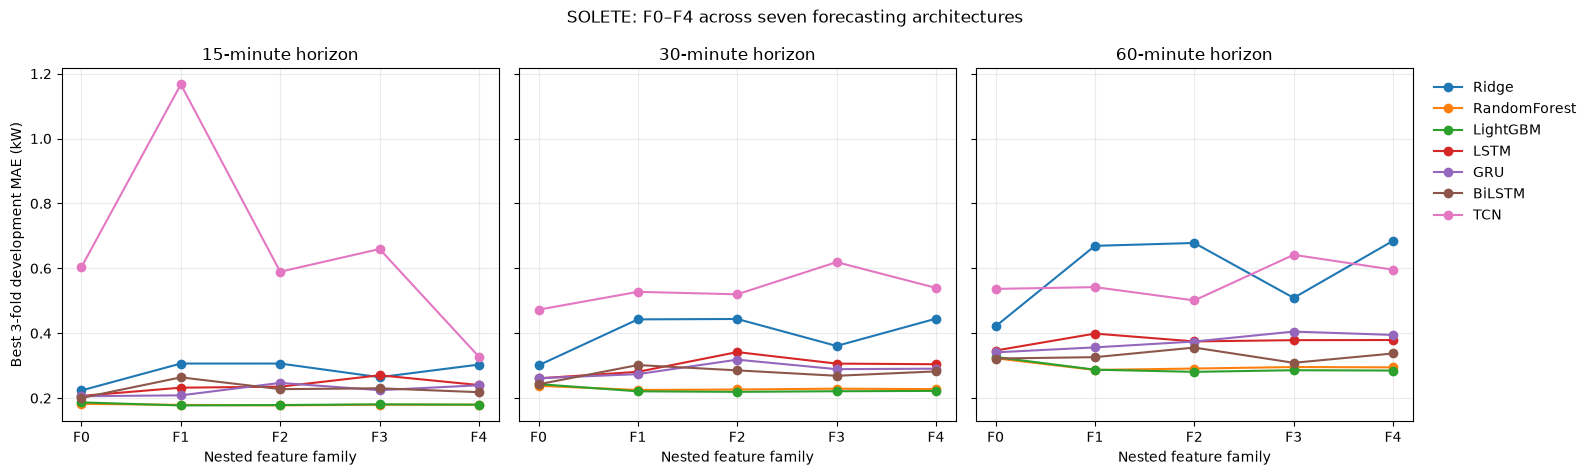

In [5]:
fig, axes=plt.subplots(1,3,figsize=(16,4.8),sharey=True)
for ax,h in zip(axes,HORIZONS):
    for model in MODELS:
        values=progression.loc[(model,h),list(FAMILIES)].to_numpy(dtype=float)
        ax.plot(FAMILIES,values,marker='o',linewidth=1.5,label=model)
    ax.set_title(f'{h}-minute horizon')
    ax.set_xlabel('Nested feature family')
    ax.grid(alpha=.25)
axes[0].set_ylabel('Best 3-fold development MAE (kW)')
axes[-1].legend(loc='upper left',bbox_to_anchor=(1.02,1.0),frameon=False)
fig.suptitle('SOLETE: F0–F4 across seven forecasting architectures')
fig.tight_layout()
plt.show()

## 6. Primary F3–F4 analysis: matched candidate configurations and folds

For each architecture, horizon, configuration and fold, F3 and F4 use the same training/validation populations. The signed paired effect is

\[
\Delta_{F4} = \operatorname{MAE}(F3)-\operatorname{MAE}(F4).
\]

Positive values favor the Panchang-augmented F4 representation. We report all 333 matched **configuration–fold** differences, then average the three outer-fold differences within each configuration to obtain 111 distinct configuration contrasts. These are descriptive development comparisons; the three folds are not enough to establish sampling confidence intervals.

In [6]:
PAIR_KEYS=['model','horizon_minutes','config_index','fold']
f3=cv.query("feature_family == 'F3'").copy()
f4=cv.query("feature_family == 'F4'").copy()
keep=PAIR_KEYS+['train_rows','validation_rows','validation_mae_kw','validation_rmse_kw']
fold_pairs=f3[keep].merge(f4[keep],on=PAIR_KEYS,suffixes=('_F3','_F4'),
                           validate='one_to_one')
assert len(fold_pairs)==333
assert (fold_pairs['train_rows_F3']==fold_pairs['train_rows_F4']).all()
assert (fold_pairs['validation_rows_F3']==fold_pairs['validation_rows_F4']).all()
fold_pairs['mae_reduction_kw']=fold_pairs['validation_mae_kw_F3']-fold_pairs['validation_mae_kw_F4']
fold_pairs['rmse_reduction_kw']=fold_pairs['validation_rmse_kw_F3']-fold_pairs['validation_rmse_kw_F4']
match_keys=['model','horizon_minutes','config_index']
config_pairs=(fold_pairs.groupby(match_keys,as_index=False)
              .agg(mae_reduction_kw=('mae_reduction_kw','mean'),
                   rmse_reduction_kw=('rmse_reduction_kw','mean'),
                   folds_favoring_F4=('mae_reduction_kw',lambda s:int((s>0).sum())),
                   folds=('fold','nunique')))
assert len(config_pairs)==111 and config_pairs['folds'].eq(3).all()
# Cross-validate the matched effects using independently aggregated candidate rankings.
agg_f3=candidates.query("feature_family == 'F3'")[match_keys+['cv_mae_kw']]
agg_f4=candidates.query("feature_family == 'F4'")[match_keys+['cv_mae_kw']]
check=agg_f3.merge(agg_f4,on=match_keys,suffixes=('_F3','_F4'),validate='one_to_one')
check['expected_gain']=check['cv_mae_kw_F3']-check['cv_mae_kw_F4']
config_pairs=config_pairs.merge(check[match_keys+['expected_gain']],on=match_keys,
                                validate='one_to_one')
assert np.allclose(config_pairs['mae_reduction_kw'],config_pairs['expected_gain'],atol=1e-12)
config_pairs=config_pairs.drop(columns=['expected_gain'])
print('Matched F3/F4: 333 fold pairs; 111 configuration pairs; same fold populations')

Matched F3/F4: 333 fold pairs; 111 configuration pairs; same fold populations


## 7. Architecture-specific stability of the Panchang effect

For each model/horizon we report the mean and median of its matched-configuration MAE reductions, how many configurations favor F4, and how many show F4 improvement on all three folds. The median and configuration counts are especially useful when a model has unusually unstable candidate errors. These are **within-model** summaries, not a pooled estimate of one universal Panchang effect.

In [7]:
matched_summary=(config_pairs.groupby(['model','horizon_minutes'],as_index=False)
    .agg(configurations=('config_index','size'),
         mean_mae_reduction_kw=('mae_reduction_kw','mean'),
         median_mae_reduction_kw=('mae_reduction_kw','median'),
         configurations_favoring_F4=('mae_reduction_kw',lambda s:int((s>0).sum())),
         configurations_F4_better_all_folds=('folds_favoring_F4',lambda s:int((s==3).sum()))))
matched_summary['model_order']=matched_summary['model'].map({m:i for i,m in enumerate(MODELS)})
matched_summary=matched_summary.sort_values(['model_order','horizon_minutes']).drop(columns='model_order')
assert len(matched_summary)==21
assert matched_summary['configurations'].sum()==111
assert matched_summary['configurations_favoring_F4'].le(matched_summary['configurations']).all()
print('F3−F4 matched-configuration MAE reduction (kW; positive = F4 better):')
display(matched_summary.round(6))

F3−F4 matched-configuration MAE reduction (kW; positive = F4 better):


,model,horizon_minutes,configurations,mean_mae_reduction_kw,median_mae_reduction_kw,configurations_favoring_F4,configurations_F4_better_all_folds
15,Ridge,15,5,-0.084066,-0.019751,0,0
16,Ridge,30,5,-0.133794,-0.034556,0,0
17,Ridge,60,5,-0.209565,-0.058439,0,0
12,RandomForest,15,8,0.000250,0.000088,5,3
13,RandomForest,30,8,0.000183,0.000267,5,2
14,RandomForest,60,8,-0.000060,-0.000350,2,1
9,LightGBM,15,8,-0.000308,-0.000163,4,2
10,LightGBM,30,8,-0.002039,-0.001824,2,0
11,LightGBM,60,8,0.002066,0.001672,7,1
6,LSTM,15,4,0.042648,0.045454,4,2


## 8. Separately selected F3 and F4 family winners

We also compare the lowest-MAE F3 candidate with the lowest-MAE F4 candidate **within each architecture/horizon**. Because their configurations may differ, this asks a different question from the matched-configuration analysis: which representation performs better after family-specific development tuning? The results are exploratory and are not independent test estimates.

In [8]:
f3_w=winners.query("feature_family=='F3'")[
    ['model','horizon_minutes','config_index','cv_mae_kw']]
f4_w=winners.query("feature_family=='F4'")[
    ['model','horizon_minutes','config_index','cv_mae_kw']]
tuned=f3_w.merge(f4_w,on=['model','horizon_minutes'],suffixes=('_F3','_F4'),
                 validate='one_to_one')
tuned['mae_reduction_kw']=tuned['cv_mae_kw_F3']-tuned['cv_mae_kw_F4']
tuned['mae_reduction_pct']=100*tuned['mae_reduction_kw']/tuned['cv_mae_kw_F3']
tuned['model_order']=tuned['model'].map({m:i for i,m in enumerate(MODELS)})
tuned=tuned.sort_values(['model_order','horizon_minutes']).drop(columns='model_order')
assert len(tuned)==21
print('Within-family tuned F3 vs F4:')
display(tuned.round(6))
print('F4 has lower tuned development MAE in',int(tuned['mae_reduction_kw'].gt(0).sum()),'of 21 model–horizon cases')

Within-family tuned F3 vs F4:


,model,horizon_minutes,config_index_F3,cv_mae_kw_F3,config_index_F4,cv_mae_kw_F4,mae_reduction_kw,mae_reduction_pct
0,Ridge,15,0,0.264452,4,0.303371,-0.038919,-14.716853
1,Ridge,30,0,0.360826,4,0.444886,-0.084059,-23.296399
2,Ridge,60,0,0.508959,4,0.684748,-0.175790,-34.539120
3,RandomForest,15,2,0.179622,2,0.179598,0.000024,0.013572
4,RandomForest,30,2,0.229083,2,0.227636,0.001448,0.631935
5,RandomForest,60,2,0.295827,2,0.294765,0.001062,0.359017
6,LightGBM,15,1,0.180784,0,0.179828,0.000956,0.529009
7,LightGBM,30,0,0.221195,0,0.222238,-0.001043,-0.471390
8,LightGBM,60,0,0.285970,0,0.284991,0.000979,0.342319
9,LSTM,15,0,0.270439,1,0.240270,0.030169,11.155514


F4 has lower tuned development MAE in 12 of 21 model–horizon cases


## 9. Reconcile the historical architecture search with the frozen model-selection lock

The earlier cross-architecture development search selected a model and feature family separately for each horizon. We independently recompute the minimum-MAE candidates and confirm that the frozen selection lock identifies those original development winners. These locked choices were later evaluated retrospectively; this notebook does not reselect models using retrospective scores.

In [9]:
lock_path=PROJECT_ROOT/'results'/'development_only'/'revised_model_selection_lock_v1.json'
lock=json.loads(lock_path.read_text(encoding='utf-8'))
selected=(candidates.sort_values(['horizon_minutes','cv_mae_kw','model_order','family_order',
                                   'config_index'],kind='stable')
          .drop_duplicates('horizon_minutes')
          .sort_values('horizon_minutes'))
assert len(selected)==3
checks=[]
for record in lock['selected_candidates']:
    h=int(record['horizon_minutes'])
    proposed=selected.loc[selected['horizon_minutes']==h].iloc[0]
    assert proposed['model']==record['model']
    assert proposed['feature_family']==record['feature_family']
    assert json.loads(proposed['configuration_json'])==record['configuration']
    checks.append({'horizon_minutes':h,'model':proposed['model'],
                   'feature_family':proposed['feature_family'],
                   'candidate_id':proposed['candidate_id'],
                   'cv_mae_kw':float(proposed['cv_mae_kw'])})
assert len(checks)==3 and {r['horizon_minutes'] for r in checks}==set(HORIZONS)
selection=pd.DataFrame(checks).sort_values('horizon_minutes')
print('Previously frozen original development selection reproduced:')
display(selection.round(6))

Previously frozen original development selection reproduced:


,horizon_minutes,model,feature_family,candidate_id,cv_mae_kw
0,15,LightGBM,F1,LightGBM_C1,0.177400
1,30,LightGBM,F2,LightGBM_C1,0.219329
2,60,LightGBM,F2,LightGBM_C1,0.280951


## 10. Reconcile archived LightGBM C1 with the newer unified Notebook 08

Notebook 08 independently refitted the fixed LightGBM C1 model for the latest SOLETE study. We align its **all-hours, fold-level F0–F4 errors** with the earlier LightGBM C1 archive and report any differences directly. The two are distinct recorded executions; matching fold counts alone does not demonstrate identical fitted predictions or feature construction. We retain both sources rather than replacing one with the other.

In [10]:
newer_path=PROJECT_ROOT/'results'/'feature_comparison'/'solete_development_fold_metrics.csv'
if not newer_path.is_file():
    raise FileNotFoundError(newer_path)
newer=pd.read_csv(newer_path)
required_new={'horizon_min','fold','scope','method','mae_kw','rmse_kw'}
assert required_new.issubset(newer.columns)
newer=newer[(newer['scope']=='all') & (newer['method'].isin(FAMILIES))].copy()
newer=newer.rename(columns={'horizon_min':'horizon_minutes','method':'feature_family',
                            'mae_kw':'newer_mae_kw','rmse_kw':'newer_rmse_kw'})
legacy=cv[(cv['model']=='LightGBM')&(cv['config_index']==0)].copy()
legacy=legacy.rename(columns={'validation_mae_kw':'archived_mae_kw',
                              'validation_rmse_kw':'archived_rmse_kw'})
reconcile=legacy[['horizon_minutes','fold','feature_family','archived_mae_kw',
                  'archived_rmse_kw']].merge(
       newer[['horizon_minutes','fold','feature_family','newer_mae_kw','newer_rmse_kw']],
       on=['horizon_minutes','fold','feature_family'],validate='one_to_one')
assert len(reconcile)==3*3*5==45
reconcile['new_minus_archive_mae_kw']=reconcile['newer_mae_kw']-reconcile['archived_mae_kw']
reconcile['new_minus_archive_rmse_kw']=reconcile['newer_rmse_kw']-reconcile['archived_rmse_kw']
reconciliation_summary=(reconcile.groupby(['horizon_minutes','feature_family'],as_index=False)
    .agg(mean_new_minus_archive_mae_kw=('new_minus_archive_mae_kw','mean'),
         max_abs_mae_gap_kw=('new_minus_archive_mae_kw',lambda x:float(np.abs(x).max())),
         max_abs_rmse_gap_kw=('new_minus_archive_rmse_kw',lambda x:float(np.abs(x).max()))))
print('LightGBM C1 development-run reconciliation (two separately executed studies):')
display(reconciliation_summary.round(6))
print('Identical stored fold MAE values:',int(np.isclose(reconcile['new_minus_archive_mae_kw'],
                                                       0,atol=1e-10,rtol=0).sum()),'of 45')

LightGBM C1 development-run reconciliation (two separately executed studies):


,horizon_minutes,feature_family,mean_new_minus_archive_mae_kw,max_abs_mae_gap_kw,max_abs_rmse_gap_kw
0,15,F0,0.000144,0.000368,0.000817
1,15,F1,-0.000055,0.000744,0.000743
2,15,F2,-0.000445,0.001469,0.000965
3,15,F3,-0.000547,0.001029,0.000550
4,15,F4,-0.000643,0.001054,0.001218
5,30,F0,-0.000058,0.001091,0.003460
6,30,F1,0.000938,0.001606,0.001728
7,30,F2,-0.000220,0.001132,0.003427
8,30,F3,0.001582,0.003279,0.001849
9,30,F4,-0.000339,0.000657,0.001113


Identical stored fold MAE values: 0 of 45


## 11. Scientific interpretation

- **The full F0–F4 progression** shows how conventional temporal features, solar geometry, continuous lunar geometry, and categorical Panchang indicators affect each architecture's development error.
- **F3 versus F4 is the principal representation question.** It is evaluated with identical architecture, hyperparameters, horizon and fold populations. The paired differences are small for some tree models and large or unstable for some other architectures; averaging them into a single universal effect would obscure heterogeneity.
- **Selected F3/F4 candidates** describe the additional impact of development tuning and are separated from matched-configuration comparisons.
- **Neural scaling versions differ for F0 versus F1–F4**, so that incremental comparison needs the documented caveat. All F3–F4 neural contrasts remain within the V2 scaling policy.
- **All-hours development results are not daylight-only evaluation.** The new LightGBM notebooks also report daylight-specific scores on matched predictions; comparable daylight scores are not available for every architecture in these archived fold tables.
- This is a **retrospective exploratory comparison**. Multiple configurations and three outer folds do not constitute independent replication or uncertainty estimates for training-seed variation. The separately evaluated SOLETE and PVOD work should be discussed as distinct evidence, not mixed into the development ranking.

## 12. Save the SOLETE cross-architecture synthesis

We save the full 21-row architecture × horizon × F0–F4 matrix, all 84 incremental family comparisons, the 333 paired F3–F4 fold contrasts, the 111 matched configurations, 21 architecture/horizon summaries and family-specific tuned comparisons, and the LightGBM C1 reconciliation. These tables support the final scientific write-up without rerunning the archived candidate search.

In [11]:
OUTPUT.mkdir(parents=True,exist_ok=True)
artifacts={
    'solete_architecture_family_progression.csv':progression.reset_index(),
    'solete_architecture_incremental_effects.csv':increments,
    'solete_architecture_f3_f4_fold_pairs.csv':fold_pairs,
    'solete_architecture_f3_f4_config_pairs.csv':config_pairs,
    'solete_architecture_f3_f4_model_summary.csv':matched_summary,
    'solete_architecture_f3_f4_tuned_comparison.csv':tuned,
    'solete_architecture_selection_reconciliation.csv':selection,
    'solete_lightgbm_run_reconciliation.csv':reconcile,
    'solete_lightgbm_reconciliation_summary.csv':reconciliation_summary,
}
expected_rows={
    'solete_architecture_family_progression.csv':21,
    'solete_architecture_incremental_effects.csv':84,
    'solete_architecture_f3_f4_fold_pairs.csv':333,
    'solete_architecture_f3_f4_config_pairs.csv':111,
    'solete_architecture_f3_f4_model_summary.csv':21,
    'solete_architecture_f3_f4_tuned_comparison.csv':21,
    'solete_architecture_selection_reconciliation.csv':3,
    'solete_lightgbm_run_reconciliation.csv':45,
    'solete_lightgbm_reconciliation_summary.csv':15,
}
for name,frame in artifacts.items():
    assert len(frame)==expected_rows[name],(name,len(frame))
    target=OUTPUT/name
    frame.to_csv(target,index=False,float_format='%.12g')
    assert len(pd.read_csv(target))==expected_rows[name]
    print(name,':',len(frame),'rows')
assert len(cv)==1665 and len(candidates)==555 and len(config_pairs)==111
print('NOTEBOOK 14: SOLETE CROSS-ARCHITECTURE SYNTHESIS CHECKS PASSED')

solete_architecture_family_progression.csv : 21 rows
solete_architecture_incremental_effects.csv : 84 rows
solete_architecture_f3_f4_fold_pairs.csv : 333 rows
solete_architecture_f3_f4_config_pairs.csv : 111 rows
solete_architecture_f3_f4_model_summary.csv : 21 rows
solete_architecture_f3_f4_tuned_comparison.csv : 21 rows
solete_architecture_selection_reconciliation.csv : 3 rows
solete_lightgbm_run_reconciliation.csv : 45 rows
solete_lightgbm_reconciliation_summary.csv : 15 rows
NOTEBOOK 14: SOLETE CROSS-ARCHITECTURE SYNTHESIS CHECKS PASSED
